In [7]:
import fastf1
import seaborn as sns

In [8]:
session = fastf1.get_session(2026, "Dutch Grand Prix", "Qualifying")
session.load()
session.results

core           INFO 	Loading data for Dutch Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['1', '63', '12', '81', '44', '16', '3', '30', '5', '41', '10', '22', '27', '43', '31', '23', '55', '14', '18', '87', '77', '11']


,DriverNumber,BroadcastName,Abbreviation,DriverId,TeamName,TeamColor,TeamId,FirstName,LastName,FullName,...,Position,ClassifiedPosition,GridPosition,Q1,Q2,Q3,Time,Status,Points,Laps
1,1,L NORRIS,NOR,norris,McLaren,F47600,mclaren,Lando,Norris,Lando Norris,...,1.0,,NaN,0 days 00:01:12.695000,0 days 00:01:11.628000,0 days 00:01:11.163000,NaT,,NaN,NaN
63,63,G RUSSELL,RUS,russell,Mercedes,00D7B6,mercedes,George,Russell,George Russell,...,2.0,,NaN,0 days 00:01:12.924000,0 days 00:01:11.959000,0 days 00:01:11.265000,NaT,,NaN,NaN
12,12,K ANTONELLI,ANT,antonelli,Mercedes,00D7B6,mercedes,Kimi,Antonelli,Kimi Antonelli,...,3.0,,NaN,0 days 00:01:13.022000,0 days 00:01:11.915000,0 days 00:01:11.296000,NaT,,NaN,NaN
81,81,O PIASTRI,PIA,piastri,McLaren,F47600,mclaren,Oscar,Piastri,Oscar Piastri,...,4.0,,NaN,0 days 00:01:12.610000,0 days 00:01:11.641000,0 days 00:01:11.305000,NaT,,NaN,NaN
44,44,L HAMILTON,HAM,hamilton,Ferrari,ED1131,ferrari,Lewis,Hamilton,Lewis Hamilton,...,5.0,,NaN,0 days 00:01:12.673000,0 days 00:01:11.970000,0 days 00:01:11.494000,NaT,,NaN,NaN
16,16,C LECLERC,LEC,leclerc,Ferrari,ED1131,ferrari,Charles,Leclerc,Charles Leclerc,...,6.0,,NaN,0 days 00:01:13.064000,0 days 00:01:11.910000,0 days 00:01:11.558000,NaT,,NaN,NaN
3,3,M VERSTAPPEN,VER,max_verstappen,Red Bull Racing,4781D7,red_bull,Max,Verstappen,Max Verstappen,...,7.0,,NaN,0 days 00:01:13.290000,0 days 00:01:11.874000,0 days 00:01:11.618000,NaT,,NaN,NaN
30,30,L LAWSON,LAW,lawson,Red Bull Racing,4781D7,red_bull,Liam,Lawson,Liam Lawson,...,8.0,,NaN,0 days 00:01:13.392000,0 days 00:01:12.301000,0 days 00:01:11.733000,NaT,,NaN,NaN
5,5,G BORTOLETO,BOR,bortoleto,Audi,F50537,audi,Gabriel,Bortoleto,Gabriel Bortoleto,...,9.0,,NaN,0 days 00:01:13.142000,0 days 00:01:12.433000,0 days 00:01:12.079000,NaT,,NaN,NaN
41,41,A LINDBLAD,LIN,arvid_lindblad,Racing Bulls,6C98FF,rb,Arvid,Lindblad,Arvid Lindblad,...,10.0,,NaN,0 days 00:01:13.074000,0 days 00:01:12.525000,0 days 00:01:12.185000,NaT,,NaN,NaN


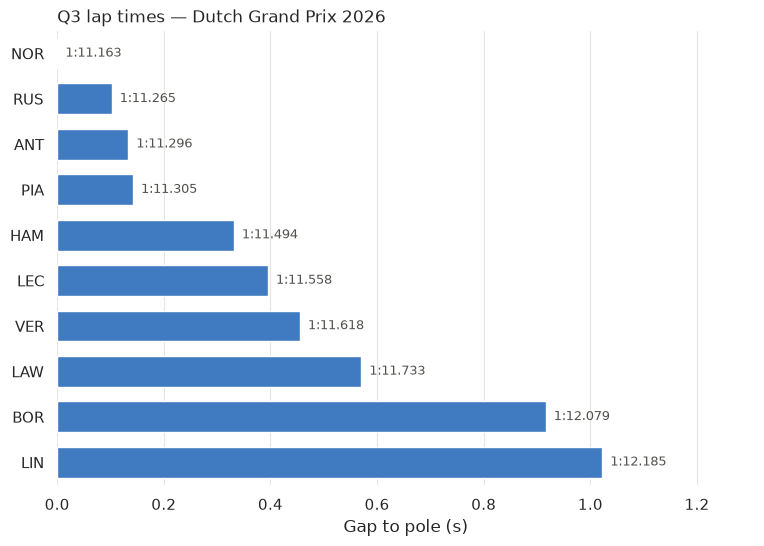

In [9]:
import matplotlib.pyplot as plt

res = session.results.copy()
res["Q3_sec"] = res["Q3"].dt.total_seconds()
res = res.dropna(subset=["Q3_sec"]).sort_values("Q3_sec")
res["Gap"] = res["Q3_sec"] - res["Q3_sec"].min()

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(res) + 1.4))
sns.barplot(data=res, y="Abbreviation", x="Gap", color="#2a78d6", width=0.68, ax=ax)

for bar, s in zip(ax.patches, res["Q3_sec"]):
    ax.text(
        bar.get_width() + res["Gap"].max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{int(s // 60)}:{s % 60:06.3f}",
        va="center",
        ha="left",
        fontsize=9,
        color="#52514e",
    )

ax.set_xlim(0, res["Gap"].max() * 1.28)
ax.set_xlabel("Gap to pole (s)")
ax.set_ylabel("")
ax.set_title("Q3 lap times \u2014 Dutch Grand Prix 2026", loc="left")
ax.xaxis.grid(True, color="#e6e5e2", lw=0.8)
ax.yaxis.grid(False)
sns.despine(left=True, bottom=True)

In [10]:
session.laps.head()

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 00:18:14.116000,NOR,1,NaT,1.0,1.0,0 days 00:16:47.086000,NaT,NaT,0 days 00:00:29.478000,...,False,McLaren,0 days 00:16:47.086000,2026-08-22 14:03:22.850,1,NaN,False,,False,False
1,0 days 00:19:36.032000,NOR,1,0 days 00:01:21.916000,2.0,1.0,NaT,NaT,0 days 00:00:27.948000,0 days 00:00:28.003000,...,False,McLaren,0 days 00:18:14.116000,2026-08-22 14:04:49.880,1,NaN,False,,False,True
2,0 days 00:20:49.092000,NOR,1,0 days 00:01:13.060000,3.0,1.0,NaT,NaT,0 days 00:00:25.162000,0 days 00:00:25.717000,...,False,McLaren,0 days 00:19:36.032000,2026-08-22 14:06:11.796,1,NaN,False,,False,True
3,0 days 00:22:29.924000,NOR,1,0 days 00:01:40.832000,4.0,1.0,NaT,0 days 00:22:27.411000,0 days 00:00:34.663000,0 days 00:00:31.557000,...,False,McLaren,0 days 00:20:49.092000,2026-08-22 14:07:24.856,1,NaN,False,,False,False
4,0 days 00:28:02.660000,NOR,1,NaT,5.0,2.0,0 days 00:26:34.169000,NaT,NaT,0 days 00:00:28.482000,...,False,McLaren,0 days 00:22:29.924000,2026-08-22 14:09:05.688,1,NaN,False,,False,False


In [11]:
session.laps.pick_teams("Red Bull Racing").sort_values("LapTime").head()

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
151,0 days 01:09:56.406000,VER,3,0 days 00:01:11.618000,21.0,5.0,NaT,NaT,0 days 00:00:24.533000,0 days 00:00:25.320000,...,True,Red Bull Racing,0 days 01:08:44.788000,2026-08-22 14:55:20.552,1,NaN,False,,False,True
148,0 days 01:04:32.861000,VER,3,0 days 00:01:11.677000,18.0,4.0,NaT,NaT,0 days 00:00:24.543000,0 days 00:00:25.263000,...,True,Red Bull Racing,0 days 01:03:21.184000,2026-08-22 14:49:56.948,1,NaN,False,,False,True
176,0 days 01:10:01.724000,LAW,30,0 days 00:01:11.733000,24.0,6.0,NaT,NaT,0 days 00:00:24.574000,0 days 00:00:25.221000,...,True,Red Bull Racing,0 days 01:08:49.991000,2026-08-22 14:55:25.755,1,NaN,False,,False,True
173,0 days 01:04:44.889000,LAW,30,0 days 00:01:11.811000,21.0,5.0,NaT,NaT,0 days 00:00:24.682000,0 days 00:00:25.234000,...,True,Red Bull Racing,0 days 01:03:33.078000,2026-08-22 14:50:08.842,1,NaN,False,,False,True
144,0 days 00:51:47.538000,VER,3,0 days 00:01:11.874000,14.0,3.0,NaT,NaT,0 days 00:00:24.769000,0 days 00:00:25.304000,...,True,Red Bull Racing,0 days 00:50:35.664000,2026-08-22 14:37:11.428,1,NaN,False,,False,True


In [12]:
session.laps[session.laps["Driver"] == "VER"].get_car_data().head()

,Date,RPM,Speed,nGear,Throttle,Brake,DRS,Source,Time,SessionTime
0,2026-08-22 14:01:15.572,3590.0,14.0,1,0.0,False,0,car,0 days 00:00:00.226000,0 days 00:14:39.808000
1,2026-08-22 14:01:16.693,3288.0,25.0,1,0.0,False,0,car,0 days 00:00:01.347000,0 days 00:14:40.929000
2,2026-08-22 14:01:17.013,3289.0,28.0,1,0.0,False,0,car,0 days 00:00:01.667000,0 days 00:14:41.249000
3,2026-08-22 14:01:17.213,3554.0,31.0,1,0.0,False,0,car,0 days 00:00:01.867000,0 days 00:14:41.449000
4,2026-08-22 14:01:17.493,3672.0,33.0,1,0.0,False,0,car,0 days 00:00:02.147000,0 days 00:14:41.729000


In [ ]:
print(session.weather_data.columns)
session.weather_data.head()

Index(['Time', 'AirTemp', 'Humidity', 'Pressure', 'Rainfall', 'TrackTemp',
       'WindDirection', 'WindSpeed'],
      dtype='object')


,Time,AirTemp,Humidity,Pressure,Rainfall,TrackTemp,WindDirection,WindSpeed
0,0 days 00:00:22.921000,18.2,56.3,1020.6,False,34.3,77,1.9
1,0 days 00:01:23.132000,18.3,55.7,1020.6,False,34.5,50,1.3
2,0 days 00:02:23.187000,18.3,55.4,1020.6,True,33.3,63,3.1
3,0 days 00:03:22.929000,18.4,56.4,1020.6,False,32.0,24,2.7
4,0 days 00:04:23.803000,18.4,56.0,1020.7,False,31.9,76,2.5


In [14]:
fastf1.get_event_schedule(2025)

,RoundNumber,Country,Location,OfficialEventName,EventDate,EventName,EventFormat,Session1,Session1Date,Session1DateUtc,...,Session3,Session3Date,Session3DateUtc,Session4,Session4Date,Session4DateUtc,Session5,Session5Date,Session5DateUtc,F1ApiSupport
0,0,Bahrain,Sakhir,FORMULA 1 ARAMCO PRE-SEASON TESTING 2025,2025-02-28,Pre-Season Testing,testing,Practice 1,2025-02-26 10:00:00+03:00,2025-02-26 07:00:00,...,Practice 3,2025-02-28 10:00:00+03:00,2025-02-28 07:00:00,None,NaT,NaT,None,NaT,NaT,True
1,1,Australia,Melbourne,FORMULA 1 LOUIS VUITTON AUSTRALIAN GRAND PRIX ...,2025-03-16,Australian Grand Prix,conventional,Practice 1,2025-03-14 12:30:00+11:00,2025-03-14 01:30:00,...,Practice 3,2025-03-15 12:30:00+11:00,2025-03-15 01:30:00,Qualifying,2025-03-15 16:00:00+11:00,2025-03-15 05:00:00,Race,2025-03-16 15:00:00+11:00,2025-03-16 04:00:00,True
2,2,China,Shanghai,FORMULA 1 HEINEKEN CHINESE GRAND PRIX 2025,2025-03-23,Chinese Grand Prix,sprint_qualifying,Practice 1,2025-03-21 11:30:00+08:00,2025-03-21 03:30:00,...,Sprint,2025-03-22 11:00:00+08:00,2025-03-22 03:00:00,Qualifying,2025-03-22 15:00:00+08:00,2025-03-22 07:00:00,Race,2025-03-23 15:00:00+08:00,2025-03-23 07:00:00,True
3,3,Japan,Suzuka,FORMULA 1 LENOVO JAPANESE GRAND PRIX 2025,2025-04-06,Japanese Grand Prix,conventional,Practice 1,2025-04-04 11:30:00+09:00,2025-04-04 02:30:00,...,Practice 3,2025-04-05 11:30:00+09:00,2025-04-05 02:30:00,Qualifying,2025-04-05 15:00:00+09:00,2025-04-05 06:00:00,Race,2025-04-06 14:00:00+09:00,2025-04-06 05:00:00,True
4,4,Bahrain,Sakhir,FORMULA 1 GULF AIR BAHRAIN GRAND PRIX 2025,2025-04-13,Bahrain Grand Prix,conventional,Practice 1,2025-04-11 14:30:00+03:00,2025-04-11 11:30:00,...,Practice 3,2025-04-12 15:30:00+03:00,2025-04-12 12:30:00,Qualifying,2025-04-12 19:00:00+03:00,2025-04-12 16:00:00,Race,2025-04-13 18:00:00+03:00,2025-04-13 15:00:00,True
5,5,Saudi Arabia,Jeddah,FORMULA 1 STC SAUDI ARABIAN GRAND PRIX 2025,2025-04-20,Saudi Arabian Grand Prix,conventional,Practice 1,2025-04-18 16:30:00+03:00,2025-04-18 13:30:00,...,Practice 3,2025-04-19 16:30:00+03:00,2025-04-19 13:30:00,Qualifying,2025-04-19 20:00:00+03:00,2025-04-19 17:00:00,Race,2025-04-20 20:00:00+03:00,2025-04-20 17:00:00,True
6,6,United States,Miami Gardens,FORMULA 1 CRYPTO.COM MIAMI GRAND PRIX 2025,2025-05-04,Miami Grand Prix,sprint_qualifying,Practice 1,2025-05-02 12:30:00-04:00,2025-05-02 16:30:00,...,Sprint,2025-05-03 12:00:00-04:00,2025-05-03 16:00:00,Qualifying,2025-05-03 16:00:00-04:00,2025-05-03 20:00:00,Race,2025-05-04 16:00:00-04:00,2025-05-04 20:00:00,True
7,7,Italy,Imola,FORMULA 1 AWS GRAN PREMIO DEL MADE IN ITALY E ...,2025-05-18,Emilia Romagna Grand Prix,conventional,Practice 1,2025-05-16 13:30:00+02:00,2025-05-16 11:30:00,...,Practice 3,2025-05-17 12:30:00+02:00,2025-05-17 10:30:00,Qualifying,2025-05-17 16:00:00+02:00,2025-05-17 14:00:00,Race,2025-05-18 15:00:00+02:00,2025-05-18 13:00:00,True
8,8,Monaco,Monaco,FORMULA 1 TAG HEUER GRAND PRIX DE MONACO 2025,2025-05-25,Monaco Grand Prix,conventional,Practice 1,2025-05-23 13:30:00+02:00,2025-05-23 11:30:00,...,Practice 3,2025-05-24 12:30:00+02:00,2025-05-24 10:30:00,Qualifying,2025-05-24 16:00:00+02:00,2025-05-24 14:00:00,Race,2025-05-25 15:00:00+02:00,2025-05-25 13:00:00,True
9,9,Spain,Barcelona,FORMULA 1 ARAMCO GRAN PREMIO DE ESPAÑA 2025,2025-06-01,Spanish Grand Prix,conventional,Practice 1,2025-05-30 13:30:00+02:00,2025-05-30 11:30:00,...,Practice 3,2025-05-31 12:30:00+02:00,2025-05-31 10:30:00,Qualifying,2025-05-31 16:00:00+02:00,2025-05-31 14:00:00,Race,2025-06-01 15:00:00+02:00,2025-06-01 13:00:00,True


In [15]:
event1950 = fastf1.get_event_schedule(1950)
print(event1950.columns)
event1950

Index(['RoundNumber', 'Country', 'Location', 'OfficialEventName', 'EventDate',
       'EventName', 'EventFormat', 'Session1', 'Session1Date',
       'Session1DateUtc', 'Session2', 'Session2Date', 'Session2DateUtc',
       'Session3', 'Session3Date', 'Session3DateUtc', 'Session4',
       'Session4Date', 'Session4DateUtc', 'Session5', 'Session5Date',
       'Session5DateUtc', 'F1ApiSupport'],
      dtype='object')


,RoundNumber,Country,Location,OfficialEventName,EventDate,EventName,EventFormat,Session1,Session1Date,Session1DateUtc,...,Session3,Session3Date,Session3DateUtc,Session4,Session4Date,Session4DateUtc,Session5,Session5Date,Session5DateUtc,F1ApiSupport
0,1,UK,Silverstone,,1950-05-13,British Grand Prix,conventional,Practice 1,None,1950-05-11,...,Practice 3,None,1950-05-12,Qualifying,None,1950-05-12,Race,None,1950-05-13,False
1,2,Monaco,Monte Carlo,,1950-05-21,Monaco Grand Prix,conventional,Practice 1,None,1950-05-19,...,Practice 3,None,1950-05-20,Qualifying,None,1950-05-20,Race,None,1950-05-21,False
2,3,USA,Indianapolis,,1950-05-30,Indianapolis 500,conventional,Practice 1,None,1950-05-28,...,Practice 3,None,1950-05-29,Qualifying,None,1950-05-29,Race,None,1950-05-30,False
3,4,Switzerland,Bern,,1950-06-04,Swiss Grand Prix,conventional,Practice 1,None,1950-06-02,...,Practice 3,None,1950-06-03,Qualifying,None,1950-06-03,Race,None,1950-06-04,False
4,5,Belgium,Spa,,1950-06-18,Belgian Grand Prix,conventional,Practice 1,None,1950-06-16,...,Practice 3,None,1950-06-17,Qualifying,None,1950-06-17,Race,None,1950-06-18,False
5,6,France,Reims,,1950-07-02,French Grand Prix,conventional,Practice 1,None,1950-06-30,...,Practice 3,None,1950-07-01,Qualifying,None,1950-07-01,Race,None,1950-07-02,False
6,7,Italy,Monza,,1950-09-03,Italian Grand Prix,conventional,Practice 1,None,1950-09-01,...,Practice 3,None,1950-09-02,Qualifying,None,1950-09-02,Race,None,1950-09-03,False


In [16]:
session = event1950.get_event_by_round(1).get_race()
session.load()
session.results.head()

core           INFO 	Loading data for British Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
core        WARNING 	Session results contain duplicate entries for driver(s) ['10', '9']
core        WARNING 	Cannot load laps, telemetry, weather, and message data because the relevant API is not supported for this session.
core           INFO 	Finished loading data for 21 drivers: ['2', '3', '4', '14', '15', '12', '11', '16', '6', '10', '18', '1', '23', '21', '5', '24', '20', '19', '17', '9', '8']


,DriverNumber,BroadcastName,Abbreviation,DriverId,TeamName,TeamColor,TeamId,FirstName,LastName,FullName,...,Position,ClassifiedPosition,GridPosition,Q1,Q2,Q3,Time,Status,Points,Laps
DriverNumber,,,,,,,,,,,,,,,,,,,,,
2,2,,,farina,Alfa Romeo,,alfa,Nino,Farina,Nino Farina,...,1.0,1,1.0,NaT,NaT,NaT,0 days 02:13:23.600000,Finished,9.0,70.0
3,3,,,fagioli,Alfa Romeo,,alfa,Luigi,Fagioli,Luigi Fagioli,...,2.0,2,2.0,NaT,NaT,NaT,0 days 00:00:02.600000,Finished,6.0,70.0
4,4,,,reg_parnell,Alfa Romeo,,alfa,Reg,Parnell,Reg Parnell,...,3.0,3,4.0,NaT,NaT,NaT,0 days 00:00:52,Finished,4.0,70.0
14,14,,,cabantous,Talbot-Lago,,lago,Yves,Cabantous,Yves Cabantous,...,4.0,4,6.0,NaT,NaT,NaT,NaT,+2 Laps,3.0,68.0
15,15,,,rosier,Talbot-Lago,,lago,Louis,Rosier,Louis Rosier,...,5.0,5,9.0,NaT,NaT,NaT,NaT,+2 Laps,2.0,68.0


In [17]:
dutch = fastf1.get_event(2026, "Dutch")
dutch

RoundNumber                                                12
Country                                           Netherlands
Location                                            Zandvoort
OfficialEventName    FORMULA 1 HEINEKEN DUTCH GRAND PRIX 2026
EventDate                                 2026-08-23 00:00:00
EventName                                    Dutch Grand Prix
EventFormat                                 sprint_qualifying
Session1                                           Practice 1
Session1Date                        2026-08-21 12:30:00+02:00
Session1DateUtc                           2026-08-21 10:30:00
Session2                                    Sprint Qualifying
Session2Date                        2026-08-21 16:30:00+02:00
Session2DateUtc                           2026-08-21 14:30:00
Session3                                               Sprint
Session3Date                        2026-08-22 12:00:00+02:00
Session3DateUtc                           2026-08-22 10:00:00
Session4

In [18]:
race = dutch.get_race()
race.load()
race.results.head()

core           INFO 	Loading data for Dutch Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cach

,DriverNumber,BroadcastName,Abbreviation,DriverId,TeamName,TeamColor,TeamId,FirstName,LastName,FullName,...,Position,ClassifiedPosition,GridPosition,Q1,Q2,Q3,Time,Status,Points,Laps
1,1,L NORRIS,NOR,norris,McLaren,F47600,mclaren,Lando,Norris,Lando Norris,...,1.0,1,1.0,NaT,NaT,NaT,0 days 02:04:44.859000,Finished,25.0,72.0
12,12,K ANTONELLI,ANT,antonelli,Mercedes,00D7B6,mercedes,Kimi,Antonelli,Kimi Antonelli,...,2.0,2,3.0,NaT,NaT,NaT,0 days 00:00:11.536000,Finished,18.0,72.0
63,63,G RUSSELL,RUS,russell,Mercedes,00D7B6,mercedes,George,Russell,George Russell,...,3.0,3,2.0,NaT,NaT,NaT,0 days 00:00:15.906000,Finished,15.0,72.0
44,44,L HAMILTON,HAM,hamilton,Ferrari,ED1131,ferrari,Lewis,Hamilton,Lewis Hamilton,...,4.0,4,5.0,NaT,NaT,NaT,0 days 00:00:16.755000,Finished,12.0,72.0
16,16,C LECLERC,LEC,leclerc,Ferrari,ED1131,ferrari,Charles,Leclerc,Charles Leclerc,...,5.0,5,6.0,NaT,NaT,NaT,0 days 00:00:17.258000,Finished,10.0,72.0


In [26]:
race.race_control_messages

,Time,Category,Message,Status,Flag,Scope,Sector,RacingNumber,Lap
0,2026-08-23 12:12:06,Other,AWNINGS MAY BE USED,None,None,None,NaN,None,1
1,2026-08-23 12:14:21,Other,LOW GRIP DELTA ACTIVE,None,None,None,NaN,None,1
2,2026-08-23 12:14:24,Other,LOW GRIP CONDITIONS,None,None,None,NaN,None,1
3,2026-08-23 12:14:27,Other,OVERTAKE DISABLED,None,None,None,NaN,None,1
4,2026-08-23 12:20:01,Flag,GREEN LIGHT - PIT EXIT OPEN,None,GREEN,Track,NaN,None,1
...,...,...,...,...,...,...,...,...,...
324,2026-08-23 15:25:46,Flag,CLEAR IN TRACK SECTOR 17,None,CLEAR,Sector,17.0,None,72
325,2026-08-23 15:26:57,Flag,DOUBLE YELLOW IN TRACK SECTOR 16,None,DOUBLE YELLOW,Sector,16.0,None,72
326,2026-08-23 15:26:57,Flag,DOUBLE YELLOW IN TRACK SECTOR 17,None,DOUBLE YELLOW,Sector,17.0,None,72
327,2026-08-23 15:28:48,Flag,CLEAR IN TRACK SECTOR 16,None,CLEAR,Sector,16.0,None,72


In [20]:
race.laps.head()

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 00:58:08.742000,NOR,1,0 days 00:01:24.177000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:27.056000,...,True,McLaren,0 days 00:56:45.791000,2026-08-23 13:03:28.568,1,1.0,False,,False,False
1,0 days 01:00:11.939000,NOR,1,0 days 00:02:03.197000,2.0,1.0,NaT,0 days 01:00:10.950000,0 days 00:00:26.899000,0 days 00:00:40.058000,...,True,McLaren,0 days 00:58:08.742000,2026-08-23 13:04:51.519,125,1.0,False,,False,False
2,0 days 01:28:33.657000,NOR,1,NaT,3.0,2.0,0 days 01:26:22.390000,NaT,NaT,0 days 00:00:35.231000,...,False,McLaren,0 days 01:26:17.312000,2026-08-23 13:33:00.089,1,1.0,False,,False,False
3,0 days 01:31:52.188000,NOR,1,NaT,4.0,2.0,NaT,NaT,NaT,0 days 00:00:28.340000,...,False,McLaren,0 days 01:28:33.657000,2026-08-23 13:35:16.434,12,1.0,False,,False,False
4,0 days 01:34:18.122000,NOR,1,0 days 00:02:25.934000,5.0,2.0,NaT,NaT,0 days 00:01:35.385000,0 days 00:00:27.429000,...,False,McLaren,0 days 01:31:52.188000,2026-08-23 13:38:34.965,12,2.0,False,,False,True


In [21]:
race.laps.columns

Index(['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint',
       'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time',
       'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime',
       'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest',
       'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime',
       'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason',
       'FastF1Generated', 'IsAccurate'],
      dtype='object')